## Explore each file

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

DATA_DIR = Path("../data")
BATCH = "base"  # change to read another batch, e.g. customers_XXX.csv

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def value_pattern(values):
    #shows the shape of each value: digits become 9, letters become a or A.
    #"2023/04/09" -> "9999/99/99", "PK" -> "AA". so its easy to spot the format
    
    pattern = values.astype(str).str.replace(r"[0-9]", "9", regex=True)
    pattern = pattern.str.replace(r"[a-z]", "a", regex=True)
    pattern = pattern.str.replace(r"[A-Z]", "A", regex=True)
    return pattern


for path in sorted(DATA_DIR.glob(f"*_{BATCH}.csv")):
    # low_memory=False: look at the whole column before deciding its type
    table = pd.read_csv(path, low_memory=False)

    print(f"\n{path.name.upper()}")
    print(f"{len(table):,} rows, {table.shape[1]} columns")
    display(table.head())

    print("\nCOLUMN TYPES")
    print(table.dtypes.to_string())

    print("\nMISSING VALUES")
    missing = table.isna().sum()
    if missing.any():
        print(missing[missing > 0].to_string())
    else:
        print("none")

    print("\nFULLY DUPLICATED ROWS:", table.duplicated().sum())

    number_columns = table.select_dtypes(include="number").columns
    if len(number_columns) > 0:
        print("\nNUMBER COLUMNS")
        display(table[number_columns].describe().T)

    print("\nTEXT COLUMNS")
    text_columns = table.select_dtypes(exclude="number").columns
    for column in text_columns:
        values = table[column].dropna()
        distinct = values.nunique()
        print(f"\n{column}: {distinct:,} distinct values, {values.duplicated().sum():,} repeated")

        spaces = (values.astype(str) != values.astype(str).str.strip()).sum()
        if spaces:
            print(f"    values with leading/trailing spaces: {spaces}")

        if distinct <= 30:
            # Few values: show them all, with counts.
            print(table[column].value_counts(dropna=False).to_string())
        else:
            # Many values: look at their lengths and formats instead.
            lengths = values.astype(str).str.len().value_counts()
            print("    lengths:", lengths.head(5).to_dict())
            patterns = value_pattern(values).value_counts()
            if len(patterns) <= 20:
                print("    formats:")
                print(patterns.to_string())
            else:
                print(f"    {len(patterns):,} different formats (too many to list)")



CUSTOMERS_BASE.CSV
901,312 rows, 9 columns


,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
0,PK,c238e72e73,True,2,1,0,13.190387,1,2021-03-23 09:16:29
1,MY,d1f64e8f1c,True,8,0,0,41.763437,1,2020-12-01 04:46:26
2,PH,e0fae59ece,True,3,0,0,44.093079,2,2019-02-13 05:56:40
3,PK,09af521b9f,True,61,0,1,4925.383520,7,2020-09-08 08:18:39
4,MY,779dacab15,True,7,0,0,92.428755,1,2021-02-19 09:59:16



COLUMN TYPES
country_code                            str
customer_id                             str
mobile_verified                         str
num_orders_last_50days                int64
num_cancelled_orders_last_50days      int64
num_refund_orders_last_50days         int64
total_payment_last_50days           float64
num_associated_customers              int64
first_order_datetime                    str

MISSING VALUES
first_order_datetime    712

FULLY DUPLICATED ROWS: 0

NUMBER COLUMNS


,count,mean,std,min,25%,50%,75%,max
num_orders_last_50days,901312.0,21.711433,26.281056,0.0,5.000000,14.000000,29.000000,2162.000000
num_cancelled_orders_last_50days,901312.0,0.264327,1.005042,0.0,0.000000,0.000000,0.000000,259.000000
num_refund_orders_last_50days,901312.0,0.230790,0.856400,0.0,0.000000,0.000000,0.000000,107.000000
total_payment_last_50days,901312.0,302.180567,425.800659,0.0,51.471977,164.582166,394.230368,42569.345127
num_associated_customers,901312.0,2.685398,6.366360,1.0,1.000000,2.000000,3.000000,101.000000



TEXT COLUMNS

country_code: 7 distinct values, 901,305 repeated
country_code
MY    339134
PH    289358
PK    151877
TH     72509
BD     48044
pk       225
my       165

customer_id: 901,312 distinct values, 0 repeated
    lengths: {10: 901312}
    1,024 different formats (too many to list)

mobile_verified: 3 distinct values, 901,309 repeated
mobile_verified
True     900681
False       466
yes         165

first_order_datetime: 896,426 distinct values, 4,174 repeated
    lengths: {19: 900600}
    formats:
first_order_datetime
9999-99-99 99:99:99    900600

LABELS_BASE.CSV
950,318 rows, 4 columns


,country_code,order_id,customer_id,is_fraud
0,TH,b9ce4cdead,4a2deee064,0
1,MY,eae640c3dd,0e39f85e6d,0
2,PH,6b5eff4d8f,b88034bb7a,0
3,MY,31928238a7,b24be37d24,0
4,MY,4adec8e335,996287540f,0


... (3 outputs left out)

,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
0,PH,c285aa06a5,Delivery,antfinancial gcash,5.387819,4.0,0.00,2023/04/09
1,PH,4cd8384425,Delivery,antfinancial gcash,7.452310,6.0,0.00,2023/04/09
2,PH,aa42f97d2e,Delivery,credit card,15.588588,6.0,0.00,2023/04/09
3,PH,f3523e5896,Delivery,credit card,90.468361,70.0,0.00,2023/04/09
4,PH,5ac770f990,Delivery,payment on Delivery,8.123690,6.0,0.88,2023/04/09



COLUMN TYPES
country_code             str
order_id                 str
collect_type             str
payment_method           str
order_value          float64
num_items_ordered    float64
refund_value         float64
order_date               str

MISSING VALUES
payment_method       21501
num_items_ordered        1

FULLY DUPLICATED ROWS: 0

NUMBER COLUMNS


,count,mean,std,min,25%,50%,75%,max
order_value,949889.0,6.938344,6.461997,0.0,3.209875,5.509056,8.511989,662.875105
num_items_ordered,949888.0,3.670441,5.012157,1.0,1.000000,2.000000,4.000000,1600.000000
refund_value,949889.0,2.236194,3.921423,0.0,0.000000,0.930000,2.900000,518.000000



TEXT COLUMNS

country_code: 5 distinct values, 949,884 repeated
country_code
MY    360569
PH    281211
PK    184822
TH     63727
BD     59560

order_id: 949,886 distinct values, 3 repeated
    lengths: {10: 949889}
    1,024 different formats (too many to list)

collect_type: 3 distinct values, 949,886 repeated
collect_type
Delivery    937730
pickup       12074
delivery        85

payment_method: 20 distinct values, 928,368 repeated
payment_method
payment on Delivery       312447
cybersource               135418
online banking            124880
credit card               114242
antfinancial gcash        102657
generic creditcard         72319
balance                    25936
NaN                        21501
antfinancial bkash         17889
antfinancial truemoney      9294
boost wallet                6088
jazzcash wallet             2509
invoice                     1963
adyen hpp molpay             837
no payment                   670
cybersource applepay         584
paypal             

## Check the oddities

In [2]:
customers = pd.read_csv(DATA_DIR / f"customers_{BATCH}.csv", low_memory=False)
orders = pd.read_csv(DATA_DIR / f"orders_{BATCH}.csv", low_memory=False)
labels = pd.read_csv(DATA_DIR / f"labels_{BATCH}.csv", low_memory=False)

### Repeated order_id
Exploring the files showed 3 repeated `order_id` values. Are they the same order twice?

In [3]:
print("repeated order_id:", orders["order_id"].duplicated().sum())
print("repeated country_code + order_id:", orders.duplicated(["country_code", "order_id"]).sum())

orders[orders["order_id"].duplicated(keep=False)].sort_values("order_id")

repeated order_id: 3
repeated country_code + order_id: 0


,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
659870,MY,431b5e1fcd,Delivery,online banking,5.418000,1.0,5.62,2023/05/06
821731,PK,431b5e1fcd,Delivery,payment on Delivery,23.789866,19.0,0.92,2022/11/30
575066,BD,8bc3659dde,Delivery,payment on Delivery,2.829650,1.0,0.00,2022/11/25
864890,TH,8bc3659dde,Delivery,cybersource,1.390409,1.0,0.00,2023/02/03
46512,PH,ac6b16a277,Delivery,payment on Delivery,8.928004,5.0,0.00,2023/01/04
522731,MY,ac6b16a277,Delivery,payment on Delivery,9.066589,3.0,0.00,2022/12/17


### Do labels match their order and customer?
Labels has more rows than orders, and some country codes are lowercase. How many labels don't match?

In [4]:
labels_upper = labels.copy()
labels_upper["country_code"] = labels_upper["country_code"].str.upper()
customers_upper = customers.copy()
customers_upper["country_code"] = customers_upper["country_code"].str.upper()

check = labels.merge(orders, on=["country_code", "order_id"], how="left", indicator=True)
print("labels with no order:", (check["_merge"] == "left_only").sum())

check = labels_upper.merge(orders, on=["country_code", "order_id"], how="left", indicator=True)
print("labels with no order, after uppercasing:", (check["_merge"] == "left_only").sum())

check = labels.merge(customers, on=["country_code", "customer_id"], how="left", indicator=True)
print("labels with no customer:", (check["_merge"] == "left_only").sum())

check = labels_upper.merge(customers_upper, on=["country_code", "customer_id"], how="left", indicator=True)
print("labels with no customer, after uppercasing:", (check["_merge"] == "left_only").sum())

labels with no order: 745
labels with no order, after uppercasing: 444
labels with no customer: 762
labels with no customer, after uppercasing: 14


### Spelling variants
Do the different spellings in `collect_type` and `payment_method` collapse when lowercased?

In [5]:
print(orders["collect_type"].str.lower().value_counts().to_string())
print()
print(orders["payment_method"].str.lower().value_counts().to_string())

collect_type
delivery    937815
pickup       12074

payment_method
payment on delivery       312467
cybersource               135418
online banking            124983
credit card               114242
antfinancial gcash        102657
generic creditcard         72319
balance                    25936
antfinancial bkash         17889
antfinancial truemoney      9294
boost wallet                6088
jazzcash wallet             2509
invoice                     1963
adyen hpp molpay             837
no payment                   670
cybersource applepay         584
paypal                       367
on delivery                  160
xendit directdebit             5


### Missing payment_method
Exploring the files showed 21,501 missing. Which countries?

In [6]:
orders.loc[orders["payment_method"].isna(), "country_code"].value_counts()

country_code
MY    21501
Name: count, dtype: int64

### order_date formats
Can every date be read with one of the three formats found when exploring the files?

In [7]:
dates = orders["order_date"]
slash = pd.to_datetime(dates, format="%Y/%m/%d", errors="coerce")
dash = pd.to_datetime(dates, format="%Y-%m-%d", errors="coerce")
month_name = pd.to_datetime(dates, format="%Y/%b/%d", errors="coerce")

print("YYYY/MM/DD: ", slash.notna().sum())
print("YYYY-MM-DD: ", dash.notna().sum())
print("YYYY/Mon/DD:", month_name.notna().sum())
print("none of them:", (slash.isna() & dash.isna() & month_name.isna()).sum())

YYYY/MM/DD:  949180
YYYY-MM-DD:  200
YYYY/Mon/DD: 509
none of them: 0


### Skew in the number columns
Exploring the files showed maxes far above the 75th percentile.

In [8]:
print(customers.select_dtypes("number").skew().round(1).to_string())
print()
print(orders.select_dtypes("number").skew().round(1).to_string())

num_orders_last_50days               5.4
num_cancelled_orders_last_50days    55.0
num_refund_orders_last_50days       17.5
total_payment_last_50days            8.7
num_associated_customers            12.5

order_value           6.6
num_items_ordered    41.0
refund_value          8.4


### order_value of 0

In [9]:
print("orders worth 0:", (orders["order_value"] == 0).sum())

orders worth 0: 23


### Refunds
The median refund is above 0, so most orders have a refund. Are any refunds bigger than the order?

In [10]:
print("orders with a refund:", (orders["refund_value"] > 0).sum())
print("refund bigger than order_value:", (orders["refund_value"] > orders["order_value"]).sum())

orders with a refund: 581947
refund bigger than order_value: 199687


### Fraud vs not fraud

In [11]:
labels["is_fraud"].value_counts(normalize=True)

is_fraud
0    0.890033
1    0.109967
Name: proportion, dtype: float64

## Clean the data

The cleaning lives in `cleaning.py` so the ETL pipeline runs exactly the same steps.

In [12]:
import logging
import sys

# cleaning.py lives in src/amlop_ca1 so the ETL can import it too

sys.path.append("../src")
from amlop_ca1 import cleaning

# display what cleaning.py did.
logging.basicConfig(level=logging.INFO, format="%(message)s")

customers_clean = cleaning.clean_customers(customers)
orders_clean = cleaning.clean_orders(orders)
labels_clean = cleaning.clean_labels(labels)

customers: 901312 rows, 712 with no first_order_datetime
orders.payment_method: 21501 missing values filled with 'unknown'
orders: dropped 1 rows missing ['order_value', 'num_items_ordered']
orders: 949888 rows
labels: 950318 rows, fraud rate 11.00%


### Merge into one table

In [13]:
data = cleaning.merge_all(customers_clean, orders_clean, labels_clean)
print(f"{len(data):,} rows, {data.shape[1]} columns")
data.head()

merge: 950318 labels -> 949871 rows (dropped 445 with no order and 2 with no customer; 15 orders had no label)


949,871 rows, 18 columns


,country_code,order_id,customer_id,is_fraud,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime,first_order_missing
0,TH,b9ce4cdead,4a2deee064,0,delivery,payment on delivery,13.877272,1.0,4.63,2022-12-31,True,1,0,0,22.011901,3,2019-07-30 13:29:17,0
1,MY,eae640c3dd,0e39f85e6d,0,delivery,boost wallet,2.512021,1.0,3.35,2023-03-27,True,5,0,0,78.427237,2,2023-03-19 10:39:54,0
2,PH,6b5eff4d8f,b88034bb7a,0,delivery,payment on delivery,4.309368,3.0,0.00,2022-11-16,True,9,0,0,116.873000,5,2022-07-01 14:51:03,0
3,MY,31928238a7,b24be37d24,0,delivery,credit card,8.090340,1.0,4.50,2023-01-02,True,33,1,5,520.321835,1,2020-06-07 06:47:20,0
4,MY,4adec8e335,996287540f,0,delivery,unknown,8.934508,2.0,1.74,2023-04-02,True,13,0,1,239.912829,1,2022-03-15 05:05:32,0


### Check the oddities are gone

In [14]:
print(data["country_code"].value_counts().to_string())
print()
print(data["collect_type"].value_counts().to_string())
print()
print(data["payment_method"].value_counts().to_string())
print()
print(data["mobile_verified"].value_counts(dropna=False).to_string())

country_code
MY    360563
PH    281206
PK    184819
TH     63726
BD     59557

collect_type
delivery    937797
pickup       12074

payment_method
payment on delivery       312621
cybersource               135417
online banking            124980
credit card               114239
antfinancial gcash        102655
generic creditcard         72318
balance                    25936
unknown                    21501
antfinancial bkash         17888
antfinancial truemoney      9294
boost wallet                6088
jazzcash wallet             2509
invoice                     1963
adyen hpp molpay             837
no payment                   670
cybersource applepay         583
paypal                       367
xendit directdebit             5

mobile_verified
True     949232
False       639


In [15]:
print("repeated country_code + order_id:", data.duplicated(["country_code", "order_id"]).sum())
print("order_date type:", data["order_date"].dtype)
print("order_date missing:", data["order_date"].isna().sum())
print("order_date range:", data["order_date"].min(), "to", data["order_date"].max())
print("first_order_datetime range:", data["first_order_datetime"].min(), "to", data["first_order_datetime"].max())
print()
print("missing values left:")
missing = data.isna().sum()
print(missing[missing > 0].to_string())

repeated country_code + order_id: 0
order_date type: datetime64[us]
order_date missing: 0
order_date range: 2022-11-12 00:00:00 to 2023-05-11 00:00:00
first_order_datetime range: 2012-03-25 12:53:43 to 2023-05-10 20:59:37

missing values left:
first_order_datetime    771


### refund_value: possible leakage

Earlier we saw refunds bigger than the order. Fraud rate with and without a refund:

In [16]:
has_refund = data["refund_value"] > 0
data.groupby(has_refund)["is_fraud"].mean()

refund_value
False    0.283804
True     0.000000
Name: is_fraud, dtype: float64

## Distributions and outliers

Plots use a 50,000-row sample so they draw quickly. Outlier counts use all the data.

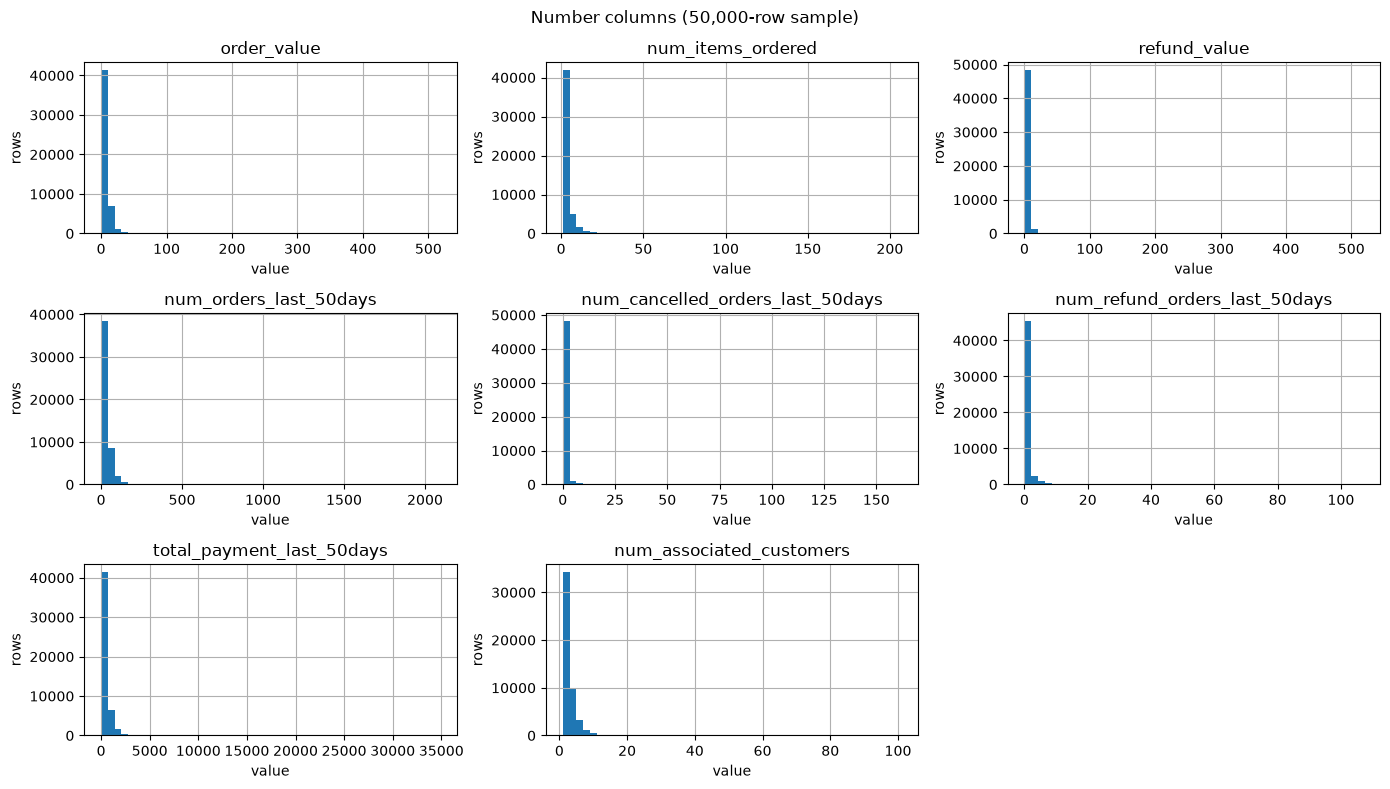

In [17]:
import matplotlib.pyplot as plt

number_columns = cleaning.ORDER_NUMERIC + cleaning.CUSTOMER_NUMERIC
sample = data.sample(min(50_000, len(data)), random_state=0)

axes = sample[number_columns].hist(bins=50, figsize=(14, 8))
for ax in axes.flatten():
    ax.set_xlabel("value")
    ax.set_ylabel("rows")
plt.suptitle("Number columns (50,000-row sample)")
plt.tight_layout()
plt.show()

### After the log transform
`add_log_features` adds a `log_` copy of each skewed column and keeps the original.

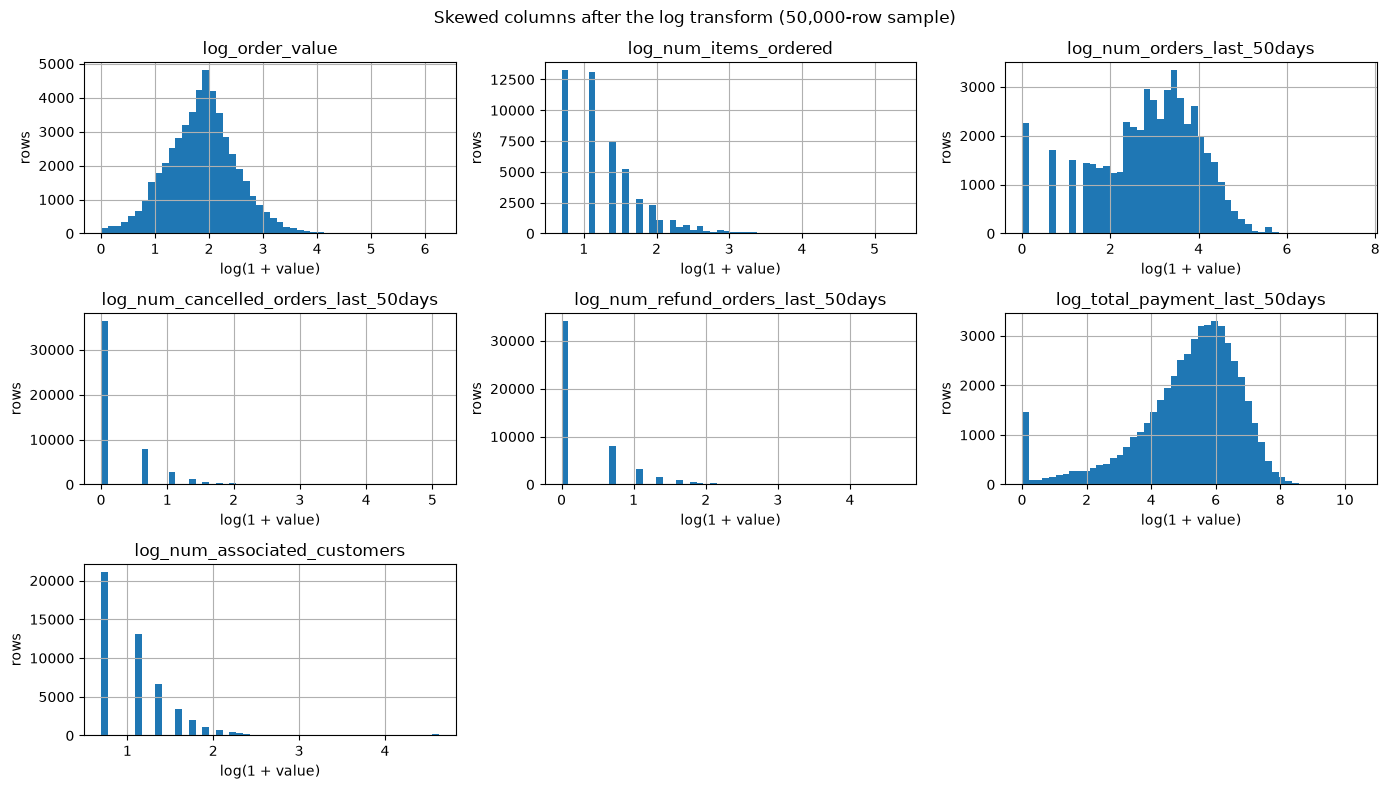

In [18]:
logged = cleaning.add_log_features(sample)
log_columns = ["log_" + column for column in cleaning.SKEWED_COLUMNS]

axes = logged[log_columns].hist(bins=50, figsize=(14, 8))
for ax in axes.flatten():
    ax.set_xlabel("log(1 + value)")
    ax.set_ylabel("rows")
plt.suptitle("Skewed columns after the log transform (50,000-row sample)")
plt.tight_layout()
plt.show()

The log makes `order_value` and `total_payment_last_50days` close to normal and evens out `num_orders_last_50days`. The count columns are still mostly 0 or 1, so the log does little for them.

### How many outliers, and are they more often fraud?
Outlier here means above Q3 + 1.5 × IQR (Tukey's rule, the same cut-off boxplot whiskers use).
For the cancelled and refund counts Q1 = Q3 = 0, so "outlier" there just means at least one.

In [19]:
print(f"overall fraud rate: {data['is_fraud'].mean():.1%}\n")

for column in number_columns:
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    is_outlier = data[column] > upper
    fraud_rate = data.loc[is_outlier, "is_fraud"].mean()
    print(f"{column}: {is_outlier.sum():,} outliers, fraud rate {fraud_rate:.1%}")

overall fraud rate: 11.0%

order_value: 56,797 outliers, fraud rate 16.9%
num_items_ordered: 69,851 outliers, fraud rate 23.5%
refund_value: 71,068 outliers, fraud rate 0.0%
num_orders_last_50days: 48,646 outliers, fraud rate 7.9%
num_cancelled_orders_last_50days: 58,980 outliers, fraud rate 16.9%
num_refund_orders_last_50days: 90,921 outliers, fraud rate 13.6%
total_payment_last_50days: 61,577 outliers, fraud rate 5.0%
num_associated_customers: 50,277 outliers, fraud rate 46.3%


## Class imbalance

is_fraud
0    845450
1    104421

8.1 non-fraud orders for every fraud order


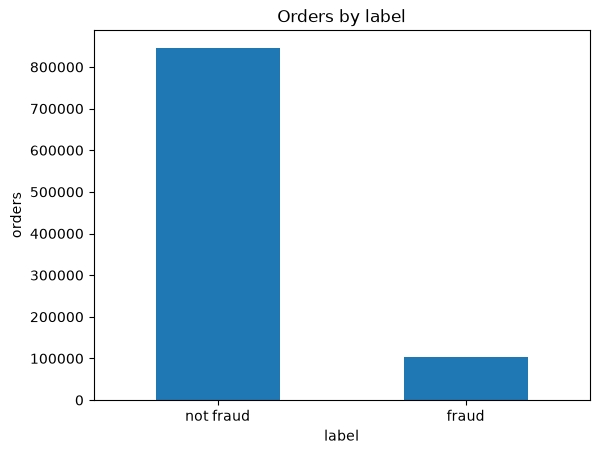

In [20]:
counts = data["is_fraud"].value_counts()
print(counts.to_string())
print(f"\n{(data['is_fraud'] == 0).sum() / (data['is_fraud'] == 1).sum():.1f} non-fraud orders for every fraud order")

counts.rename({0: "not fraud", 1: "fraud"}).plot.bar(rot=0)
plt.title("Orders by label")
plt.xlabel("label")
plt.ylabel("orders")
plt.show()

## Fraud patterns

### Country

country_code
MY    0.039
TH    0.060
PH    0.085
PK    0.245
BD    0.293


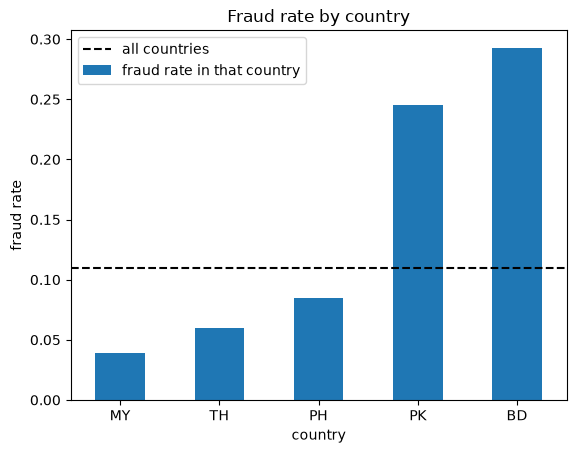

In [21]:
fraud_by_country = data.groupby("country_code")["is_fraud"].mean().sort_values()
print(fraud_by_country.round(3).to_string())

fraud_by_country.plot.bar(rot=0, label="fraud rate in that country")
plt.axhline(data["is_fraud"].mean(), color="black", linestyle="--", label="all countries")
plt.title("Fraud rate by country")
plt.xlabel("country")
plt.ylabel("fraud rate")
plt.legend()
plt.show()

### Category columns and the missing flag

In [22]:
for column in ["collect_type", "mobile_verified", "first_order_missing"]:
    print(data.groupby(column)["is_fraud"].agg(["mean", "count"]).round(3).to_string())
    print()

               mean   count
collect_type               
delivery      0.108  937797
pickup        0.288   12074

                  mean   count
mobile_verified               
False            0.116     639
True             0.110  949232

                     mean   count
first_order_missing              
0                    0.11  949100
1                    0.24     771



### Payment method

                         mean   count
payment_method                       
xendit directdebit      0.000       5
cybersource             0.033  135417
cybersource applepay    0.036     583
online banking          0.040  124980
adyen hpp molpay        0.044     837
unknown                 0.049   21501
antfinancial truemoney  0.058    9294
boost wallet            0.063    6088
paypal                  0.071     367
credit card             0.082  114239
antfinancial gcash      0.085  102655
invoice                 0.155    1963
balance                 0.160   25936
payment on delivery     0.161  312621
generic creditcard      0.194   72318
antfinancial bkash      0.260   17888
no payment              0.327     670
jazzcash wallet         0.489    2509


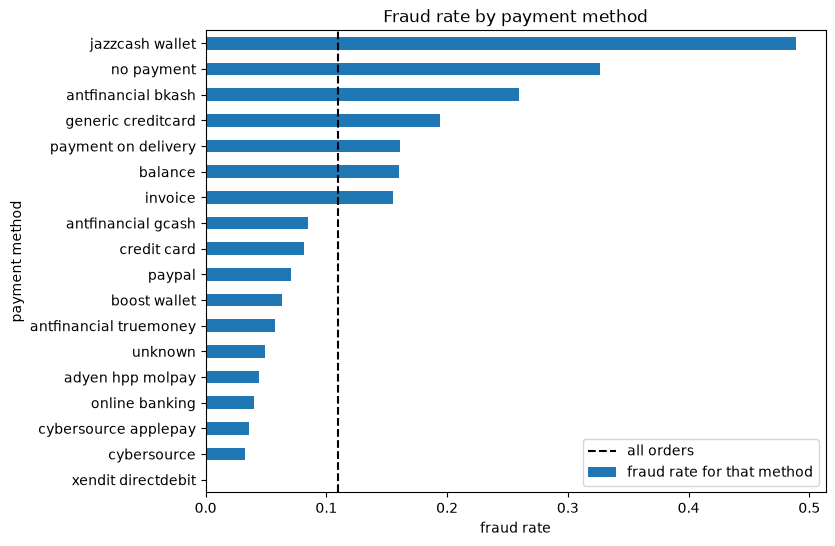

In [23]:
fraud_by_payment = data.groupby("payment_method")["is_fraud"].agg(["mean", "count"]).sort_values("mean")
print(fraud_by_payment.round(3).to_string())

fraud_by_payment["mean"].plot.barh(figsize=(8, 6), label="fraud rate for that method")
plt.axvline(data["is_fraud"].mean(), color="black", linestyle="--", label="all orders")
plt.title("Fraud rate by payment method")
plt.xlabel("fraud rate")
plt.ylabel("payment method")
plt.legend()
plt.show()

## Decisions

### Data cleaning
| Data quality issue | Tables & columns affected | How to fix |
|---|---|---|
| Lowercase country codes (390 customers, 301 labels) | customers, labels: `country_code` | Uppercase before joining |
| `mobile_verified` has "yes" next to True/False (165) | customers: `mobile_verified` | Map yes/true/false etc. to True/False |
| Missing `first_order_datetime` (712) | customers: `first_order_datetime` | Keep the rows, add a `first_order_missing` flag (24% fraud vs 11%) |
| Missing `payment_method` (21,501, all MY) | orders: `payment_method` | Fill with "unknown" |
| Missing `num_items_ordered` (1) | orders: `num_items_ordered` | Drop the row |
| Same value spelled differently (85 + 283 rows) | orders: `collect_type`, `payment_method` | Lowercase, trim, map aliases such as "on delivery" |
| Three date formats (200 `YYYY-MM-DD`, 509 `YYYY/Mon/DD`) | orders: `order_date` | Parse all three; anything else becomes NaT |
| `order_id` repeated in different countries (3) | orders, labels: `order_id` | Join on `country_code` + id |
| Labels with no order or customer (745 / 762 raw; the merge drops 445 with no order and 2 with no customer) | labels | Drop them and log the count |
| Refund bigger than the order (199,687) | orders: `refund_value` | Keep in the cleaned data (see below) |

All of this is in `cleaning.py` (`clean_customers`, `clean_orders`, `clean_labels`, `merge_all`).

### Data transformation
| Data transformation step | Which file | Why |
|---|---|---|
| Parse `order_date` and `first_order_datetime` to datetimes | `cleaning.py` | Mixed text formats can't be compared or used as features |
| `first_order_missing` flag | `cleaning.py` | Missing first order date is twice as likely to be fraud |
| Log transform of the skewed columns (`add_log_features`) | `cleaning.py` | Skew is 5 to 55; log1p makes `order_value` and `total_payment_last_50days` close to normal, the count columns stay mostly 0 |
| Keep outliers | `cleaning.py` | Outliers are often fraud, e.g. 46% for `num_associated_customers` |
| Leave `refund_value` out of model features | training code (not written yet) | Refunds happen after the fraud review; refunded orders are 0% fraud |
| Handle the 11% fraud rate with class weights, score on recall and PR-AUC | training code (not written yet) | Accuracy would look good by predicting "not fraud" for everything |